# D3.1 · Classification — from a chance of default to a flag

**Day 3 slides** 3–9

### The problem

We have many loans and a limited number of people to review them. Which loans should go to review, and how can we check our choices?

### What we’re doing

Fit a model that estimates default chances. Turn those chances into flags using a cutoff, then compare the mistakes at several cutoffs.

### Why we’re doing it

A model can look accurate because most loans do not default. We want to know how many defaults it catches and how much extra review it creates.

Read the text above a code cell, then click the cell and press
**Shift + Enter**. Run from the top. The files contain synthetic course data.

**Why the name can be confusing.** Logistic regression estimates the chance of default. A cutoff converts that chance into the final label or review flag. The question we are answering is a classification question.

## Setup · Open the data

Use the loan file. Each input is something we can know at application time. The recorded answer is default within 12 months. Use earlier years to train, 2024 to choose and 2025 for a later check in L3.1. Run this cell as written. The import lines make the tools
available. The folder lines find the supplied data.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             accuracy_score, precision_score, recall_score, f1_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from pathlib import Path

here = Path.cwd()
data = next((folder / "data" for folder in (here, *here.parents)
             if (folder / "data" / "loan_applications.csv").is_file()), None)
if data is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

inputs = ["aecb_score", "debt_burden_ratio", "loan_amount_aed", "num_prior_delinquencies_24m"]
columns = ["application_date", "default_12m", "risk_grade"] + inputs
loans = pd.read_csv(data / "loan_applications.csv", usecols=columns, parse_dates=["application_date"])
loans = loans.dropna(subset=inputs + ["default_12m"])
year = loans["application_date"].dt.year
train = loans[year <= 2023].sample(4000, random_state=42)
validation = loans[year == 2024].sample(2500, random_state=42)
test = loans[year == 2025].sample(2500, random_state=42)

print("Learn on earlier loans:", len(train))
print("Compare choices on 2024 loans:", len(validation))
print("Keep 2025 loans aside:", len(test))

Learn on earlier loans: 4000
Compare choices on 2024 loans: 2500
Keep 2025 loans aside: 2500


## 1 · Learn to guess a chance

**What we’re doing.** Train logistic regression on the earlier loans, then ask for the chance of default on each 2024 row.

**Why.** We want a number between zero and one that tells us how strongly the model thinks the answer is yes. Logistic regression turns its input score into a chance using an S-shaped curve.

**Look for.** The output contains example chances. A chance of 0.10 reads as 10%. We still need a cutoff to turn it into a flag.

In [2]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500))
model.fit(train[inputs], train["default_12m"])
actual = validation["default_12m"]
chance = model.predict_proba(validation[inputs])[:, 1]
display(pd.DataFrame({"Recorded default": actual, "Default chance": chance.round(3)}).head(6))

,Recorded default,Default chance
244417,0,0.018
231337,0,0.003
243577,0,0.003
270022,0,0.029
267818,0,0.033
277043,1,0.405


## 2 · Compare with a guess that never flags

**What we’re doing.** Ask what percentage would be correct if we guessed no default for every row.

**Why.** Accuracy means the share of all guesses we got right. A big group of easy no guesses can make accuracy look high while we miss every default.

**Look for.** The no-flag rule can have high accuracy and zero recall.

In [3]:
never_flag = np.zeros(len(actual), dtype=int)
print(f"Default share: {actual.mean():.1%}")
print(f"Always guess no · accuracy: {accuracy_score(actual, never_flag):.1%}")
print(f"Always guess no · recall: {recall_score(actual, never_flag):.1%}")

Default share: 5.9%
Always guess no · accuracy: 94.1%
Always guess no · recall: 0.0%


## 3 · Pick two cutoffs and count the mistakes

**What we’re doing.** Compare flags from a 50% cutoff and a 10% cutoff. Show accuracy, precision, recall and F1.

**Why.** Lowering the cutoff lets more loans reach review. F1 combines precision and recall and drops when either one is low.

**Look for.** Compare counts and percentages together. Which setting caught more defaults and how much extra checking did it create?

In [4]:
rows = []
for cutoff in [0.50, 0.10]:
    flagged = chance >= cutoff
    rows.append([cutoff, flagged.sum(), accuracy_score(actual, flagged),
                 precision_score(actual, flagged, zero_division=0),
                 recall_score(actual, flagged), f1_score(actual, flagged, zero_division=0)])
display(pd.DataFrame(rows, columns=["Cutoff", "Flags", "Accuracy", "Precision", "Recall", "F1"]).round(3))

,Cutoff,Flags,Accuracy,Precision,Recall,F1
0,0.5,27,0.939,0.407,0.074,0.126
1,0.1,496,0.815,0.183,0.615,0.283


### Read the other side of the confusion chart

**What we’re doing.** Look only at loans that did not default.
For the 10% cutoff, count the share we correctly clear and the
share we flag for extra review.

**Why.** These two percentages tell us how the cutoff affects the
non-default cases. They add to 100%. The second number is the
horizontal axis on the ROC chart in the next step.

In [5]:
non_defaults = actual == 0
flagged_at_ten = chance >= .10
false_positive_rate = flagged_at_ten[non_defaults].mean()

print(f"Correctly cleared · specificity: {1 - false_positive_rate:.1%}")
print(f"Flagged for extra review · false-positive rate: {false_positive_rate:.1%}")

Correctly cleared · specificity: 82.8%
Flagged for extra review · false-positive rate: 17.2%


## 4 · See all cutoffs as a picture

**What we’re doing.** Draw ROC and precision–recall curves from the same chances.

**Why.** A curve shows choices you would miss at one cutoff. ROC compares the share of defaults caught with the share of non-defaults flagged. Precision–recall shows how reliable the flags stay as we try to catch more defaults.

**Look for.** AUC summarises how well the scores rank the two classes. Average precision summarises precision and recall and is helpful when defaults are rare.

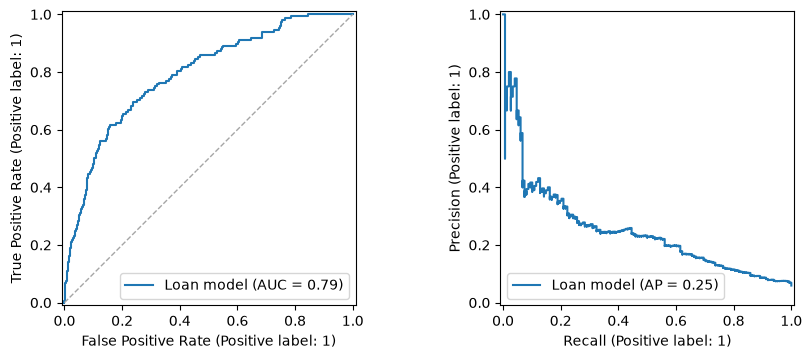

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
RocCurveDisplay.from_predictions(actual, chance, ax=axes[0], name="Loan model")
axes[0].plot([0, 1], [0, 1], "--", color="0.65", linewidth=1)
PrecisionRecallDisplay.from_predictions(actual, chance, ax=axes[1], name="Loan model")
plt.tight_layout()
plt.show()

## 5 · Give each kind of miss a cost

**What we’re doing.** Imagine a missed default costs five points and reviewing a loan that would not default costs one.

**Why.** One cutoff can be better for one goal and worse for another. Writing down the assumed costs makes the choice easy to discuss.

**Look for.** The smallest cost is the best among the tried cutoffs for this classroom cost rule and these validation rows.

In [7]:
rows = []
for cutoff in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
    flag = chance >= cutoff
    missed = ((actual == 1) & ~flag).sum()
    extra = ((actual == 0) & flag).sum()
    rows.append([cutoff, missed, extra, 5 * missed + extra])
display(pd.DataFrame(rows, columns=["Cutoff", "Missed defaults", "Extra reviews", "Cost points"]).sort_values("Cost points"))

,Cutoff,Missed defaults,Extra reviews,Cost points
2,0.15,71,263,618
3,0.20,93,174,639
4,0.30,115,75,650
1,0.10,57,405,690
5,0.50,137,16,701
0,0.05,35,792,967


## 6 · Give rare answers more weight

**What we’re doing.** Train a second logistic model that gives the rarer answer more weight while learning.

**Why.** Weighting can help the model pay more attention to defaults. It can shift the numbers it gives, which is why we still compare ranking and check the meaning of its chances.

**Look for.** Compare the average chances and the share of defaults caught at the same cutoff. L3.1 looks at whether those chances match what happened.

In [8]:
weighted = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=500))
weighted.fit(train[inputs], train["default_12m"])
weighted_chance = weighted.predict_proba(validation[inputs])[:, 1]
print(f"Average chance · original: {chance.mean():.1%} · weighted: {weighted_chance.mean():.1%}")
print(f"Recall at 10% · original: {recall_score(actual, chance >= .10):.1%} · weighted: {recall_score(actual, weighted_chance >= .10):.1%}")

Average chance · original: 7.0% · weighted: 35.7%
Recall at 10% · original: 61.5% · weighted: 99.3%


**Other ways to handle a rare class.** A trainer can use fewer common
training examples, repeat rare examples, or use SMOTE to create training
examples between nearby minority examples. Keep the original mix in
validation and test so the results reflect the group we will check.

### Your turn

Change the cost of a missed default from five points to ten. Run step 5 again and explain what happened to the cutoff. The costs and choices are classroom examples.